# Figure 2

Sam Gould, Kexin Dong

Cleaned: May 1, 2026

Last Updated: May 1, 2026

Multiplexed in vivo base editing screens identify contextual and variant-specific phenotypes.

In [1]:
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import seaborn as sns
import scipy.stats
from sklearn.decomposition import PCA
from adjustText import adjust_text
from matplotlib_venn import venn2, venn3
from upsetplot import UpSet, from_indicators
import warnings
import os
warnings.filterwarnings('ignore')

# ── Global style (matching published figures) ─────────────────────────────────────────
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype']  = 42
mpl.rcParams['text.usetex']  = False
plt.rcParams['font.family']     = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica']

blues   = sns.color_palette('Blues').as_hex()
greens  = sns.color_palette('Greens').as_hex()
reds    = sns.color_palette('Reds').as_hex()
yellows = sns.color_palette('Oranges').as_hex()
purples = sns.color_palette('Purples').as_hex()

greys = sns.color_palette('Greys').as_hex()
teals = sns.color_palette('BuPu').as_hex()
pinks = sns.color_palette('RdPu').as_hex()
browns = sns.color_palette('YlOrBr').as_hex()
BASE = '/Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/'

## 2b

The 90/10 skew ratio (counts of 90th percentile guide/counts of 10th percentile guide) for each indicated sample for ABE screen.

In [2]:
# ── Load count tables ──────────────────────────────────────────────────────
ABE_OG_COUNTS   = pd.read_csv(BASE + 'counts/og/OG_ABE_COUNTS.txt',   sep='\t')
CBE_OG_COUNTS   = pd.read_csv(BASE + 'counts/og/OG_CBE_COUNTS.txt',   sep='\t')
ABE_EPO_COUNTS  = pd.read_csv(BASE + 'counts/focused/FC_ABE_EPO_COUNTS.txt',       sep='\t')
CBE_EPO_COUNTS  = pd.read_csv(BASE + 'counts/focused/FC_CBE_EPO_COUNTS_new.txt',   sep='\t')
ABE_BC_COUNTS   = pd.read_csv(BASE + 'counts/focused/FC_ABE_BC_COUNTS.txt',        sep='\t')
CBE_BC_COUNTS   = pd.read_csv(BASE + 'counts/focused/FC_CBE_BC_COUNTS_new.txt',    sep='\t')

# ── Sample lists used in LFC-FDR (exactly mirroring LFC_FDR_calculation.ipynb) ─
# Only sample columns (no sgRNA/gene/lib annotation columns)

ABE_OG_samps = [
    'bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5',
    'meninges1','meninges2','meninges3','meninges4','meninges5',
    'spleen1','spleen2','spleen3','spleen4',
    'input_rep1','input_rep2','input_rep3',
    'd5_rep1','d5_rep2','d5_rep3',
    'd15_rep1','d15_rep2','d15_rep3',
    'plasmidlib'
]

CBE_OG_samps = [
    'bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5',
    'bonemarrow6','bonemarrow7','bonemarrow8','bonemarrow9','bonemarrow10',
    'meninges1','meninges2','meninges3','meninges4','meninges5',
    'meninges6','meninges7','meninges8','meninges9','meninges10',
    'spleen1','spleen2','spleen3','spleen4','spleen5',
    'spleen6','spleen7','spleen8','spleen9',  # spleen10 excluded
    'input_rep1','input_rep2','input_rep3',
    'd5_rep1','d5_rep2','d5_rep3',
    'd15_rep1','d15_rep2','d15_rep3',
    'plasmidlib'
]

ABE_FC_samps = [
    'bm1','bm2','bm3','bm4','bm5',
    'spleen1','spleen2','spleen3','spleen4','spleen5',
    'd15-rep1','d15-rep2','d15-rep3','d15-rep4','d15-rep5',
    'd5','input','lib'
]

# ABE BC (null): bm2 and spleen2 excluded (abnormal skewing)
ABE_BC_samps = [s for s in ABE_FC_samps if s not in ('bm2', 'spleen2')]

CBE_EPO_samps = [
    'bm1','bm3','bm4','bm6','bm7','bm9','bm10',  # bm2,5,8 excluded
    'spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10',  # spleen2,5,8 excluded
    'd15-rep1','d15-rep3','d15-rep4','d15-rep5',  # d15-rep2 excluded (abnormal skewing)
    'd5','input','lib'
]

CBE_BC_samps = [
    'bm3','bm4','bm5','bm7','bm9',  # bm1,2,6,8,10 excluded (abnormal skewing)
    'spleen3','spleen4','spleen5','spleen7','spleen9',  # spleen1,2,6,8,10 excluded (abnormal skewing)
    'd15-rep1','d15-rep2','d15-rep3','d15-rep4','d15-rep5',
    'd5','input','lib'
]

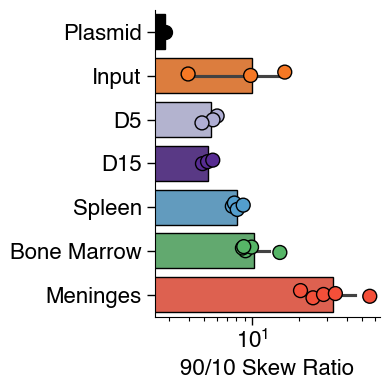

In [3]:
# ── 90/10 Skew Ratio — original figure2.ipynb style ───────────────────────
# barplot (mean per tissue group) + stripplot (individual samples), log x-scale
# Panels: OG ABE, OG CBE, Focused EPO ABE, Focused EPO CBE, Focused BC ABE, Focused BC CBE


palette_skew = ['black', yellows[3], purples[2], purples[5], blues[3], greens[3], reds[3]]
order_skew        = ['Plasmid', 'Input', 'D5', 'D15', 'Spleen', 'Bone Marrow']
order_skew_og     = ['Plasmid', 'Input', 'D5', 'D15', 'Spleen', 'Bone Marrow', 'Meninges']

# tissue label maps
_tissue_label_og = {
    'plasmidlib': 'Plasmid',
    'input_rep': 'Input',
    'd5_rep': 'D5', 'd5': 'D5',
    'd15_rep': 'D15', 'd15-rep': 'D15',
    'spleen': 'Spleen',
    'bonemarrow': 'Bone Marrow',
    'meninges': 'Meninges',
    'bm': 'Bone Marrow',
    'input': 'Input',
    'lib': 'Plasmid',
    'men': 'Meninges',
}

def _tissue_label(samp):
    for prefix, label in _tissue_label_og.items():
        if samp.startswith(prefix):
            return label
    return samp

def _skew_df(counts_df, samp_cols):
    rows = []
    for s in samp_cols:
        d = sorted(counts_df[s].values)
        n = len(d)
        ten    = d[int(0.1 * n)]
        ninety = d[int(0.9 * n)]
        ratio  = ninety / ten if ten > 0 else np.nan
        rows.append({'Sample': s, 'Name': _tissue_label(s), '90/10 Skew Ratio': ratio})
    return pd.DataFrame(rows)

def plot_skew_single(counts_df, samp_cols, label, title, order=None):
    df = _skew_df(counts_df, samp_cols)

    fig, ax = plt.subplots(figsize=(4, 4))
    _order = order if order is not None else order_skew
    _palette = palette_skew[:len(_order)]
    sns.barplot(data=df, y='Name', x='90/10 Skew Ratio', ax=ax,
                edgecolor='black', linewidth=1,
                palette=_palette, order=_order)
    sns.stripplot(data=df, y='Name', x='90/10 Skew Ratio', ax=ax,
                  edgecolor='black', linewidth=1,
                  palette=_palette, order=_order, s=10)
    ax.set_xscale('log')
    ax.xaxis.set_major_locator(mpl.ticker.LogLocator(base=10, numticks=10))
    ax.xaxis.set_major_formatter(mpl.ticker.LogFormatterMathtext())
    ax.set_ylabel('')
    ax.set_xlabel('90/10 Skew Ratio', fontsize=16)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=16, length=6, width=1, direction='out')
    ax.tick_params(axis='x', which='minor', length=3, width=0.8, direction='out')
    fig.tight_layout()
    plt.show()
    return fig

import os as _os
_os.makedirs(BASE + 'figure_final', exist_ok=True)

# OG screens
fig_abe_og = plot_skew_single(ABE_OG_COUNTS, ABE_OG_samps, 'ABE', 'OG screens', order=order_skew_og)
# fig_abe_og.savefig(BASE + 'figure_final/skew_ABE_OG.pdf', bbox_inches='tight')

# fig_cbe_og = plot_skew_single(CBE_OG_COUNTS, CBE_OG_samps, 'CBE', 'OG screens', order=order_skew_og)
# fig_cbe_og.savefig(BASE + 'figure_final/skew_CBE_OG.pdf', bbox_inches='tight')

# # Focused EPO
# fig_abe_epo = plot_skew_single(ABE_EPO_COUNTS, ABE_BC_samps, 'ABE', 'Focused EPO screens')  # ABE EPO: same exclusions as ABE BC (bm2, spleen2)
# fig_abe_epo.savefig(BASE + 'figure_final/skew_ABE_EPO.pdf', bbox_inches='tight')

# fig_cbe_epo = plot_skew_single(CBE_EPO_COUNTS, CBE_EPO_samps, 'CBE', 'Focused EPO screens')
# fig_cbe_epo.savefig(BASE + 'figure_final/skew_CBE_EPO.pdf', bbox_inches='tight')

# # Focused BC / null
# fig_abe_bc = plot_skew_single(ABE_BC_COUNTS, ABE_BC_samps, 'ABE', 'Focused BC (null) screens')
# fig_abe_bc.savefig(BASE + 'figure_final/skew_ABE_BC.pdf', bbox_inches='tight')

# fig_cbe_bc = plot_skew_single(CBE_BC_COUNTS, CBE_BC_samps, 'CBE', 'Focused BC (null) screens')
# fig_cbe_bc.savefig(BASE + 'figure_final/skew_CBE_BC.pdf', bbox_inches='tight')

## 2c

Principal components analysis of the correlation matrix of barcode counts for replicates of indicated ABE samples.

In [ ]:
CBE_counts = pd.read_csv(BASE + 'counts/og/OG_CBE_COUNTS.txt', sep='\t')
ABE_counts = pd.read_csv(BASE + 'counts/og/OG_ABE_COUNTS.txt', sep='\t')

No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.


[53.11619452 14.31995016]


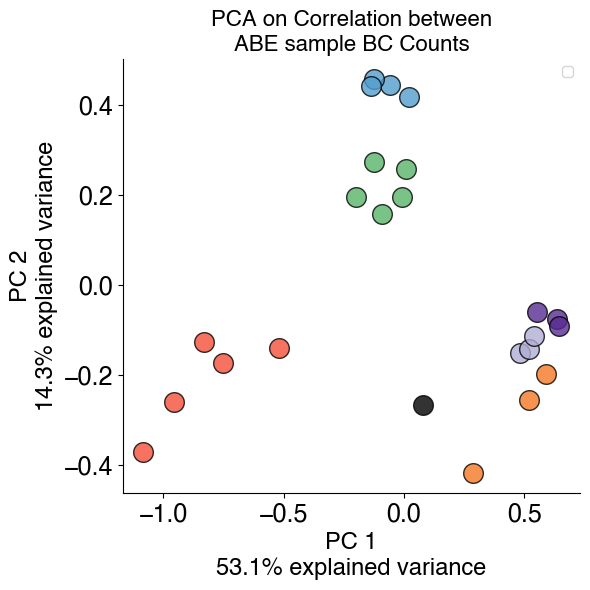

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2)
Xt = pca.fit_transform(ABE_counts.corr(method='spearman'))
fig, ax = plt.subplots(figsize=(6,6))

blues = sns.color_palette('Blues')
greens = sns.color_palette('Greens')
reds = sns.color_palette('Reds')
yellows = sns.color_palette('Oranges')
purples = sns.color_palette('Purples')

blues = blues.as_hex()
greens = greens.as_hex()
reds = reds.as_hex()
yellows = yellows.as_hex()

palette = [blues[0], blues[2], blues[3], blues[5], greens[1], greens[2], greens[3], greens[4], greens[5],  reds[1], reds[2], reds[3], reds[4], reds[5],
           yellows[1], yellows[2], yellows[3], purples[0], purples[1], purples[2], purples[3], purples[4], purples[5], 'black']

palette = [blues[3], blues[3], blues[3], blues[3], greens[3], greens[3], greens[3], greens[3], greens[3],  reds[3], reds[3], reds[3], reds[3], reds[3],
           yellows[3], yellows[3], yellows[3], purples[2], purples[2], purples[2], purples[5], purples[5], purples[5], 'black']

for i in range(len(Xt)):
    ax.scatter(Xt[i][0], Xt[i][1], edgecolor='black', s=200, alpha=.8,c=palette[i]) #,label=list(ABE_counts.columns)[i])

ax.legend(loc='best')

var = pca.explained_variance_ratio_
print(var*100)
ax.set_xlabel(f'PC 1\n{np.round(var[0]*100, 1)}% explained variance', fontsize=17)
ax.set_ylabel(f'PC 2\n{np.round(var[1]*100, 1)}% explained variance', fontsize=17)
#ax.legend(bbox_to_anchor=(1.05, 1.))
ax.spines[['top', 'right']].set_visible(False)
ax.tick_params(axis='both', which='major', labelsize=18,)
ax.set_title('PCA on Correlation between\nABE sample BC Counts', fontsize=16)
fig.tight_layout()

## 2d

Average target base editing % (with bystander edits allowed, dark blue) and pure correct editing % (no bystander edits allowed, light blue) at the sensor locus.

In [27]:
edit_palette = [blues[4], teals[2]]   # darker = target+bystander, lighter = correct only
min_sensor_reads_og = 10
min_sensor_reads_focused = 100

In [82]:
BASE = '/Users/kexindong/Documents/GitHub/B-ALL-in-vivo-base-editing/'

dfs = {
    'ABE_OG':         pd.read_csv(BASE + 'LFC-FDR/ABE_OG_LFC_FDR.csv', low_memory=False),
    'CBE_OG':         pd.read_csv(BASE + 'LFC-FDR/CBE_OG_LFC_FDR.csv', low_memory=False),
    'ABE_EPO_T0':     pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_T0_LFC_FDR.csv', low_memory=False),
    'CBE_EPO_T0':     pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_T0_LFC_FDR.csv', low_memory=False),
    'ABE_EPO_BC':     pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_TO_BC_LFC_FDR.csv', low_memory=False),
    'CBE_EPO_BC':     pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_TO_BC_LFC_FDR.csv', low_memory=False),
    'ABE_BC_T0':      pd.read_csv(BASE + 'LFC-FDR/ABE_FC_BC_T0_LFC_FDR.csv', low_memory=False),
    'CBE_BC_T0':      pd.read_csv(BASE + 'LFC-FDR/CBE_FC_BC_T0_LFC_FDR.csv', low_memory=False),
    'ABE_EPO_T0_FSR': pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_T0_LFC_FDR_FSR.csv', low_memory=False),
    'CBE_EPO_T0_FSR': pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_T0_LFC_FDR_FSR.csv', low_memory=False),
    'ABE_EPO_BC_FSR': pd.read_csv(BASE + 'LFC-FDR/ABE_FC_EPO_TO_BC_LFC_FDR_FSR.csv', low_memory=False),
    'CBE_EPO_BC_FSR': pd.read_csv(BASE + 'LFC-FDR/CBE_FC_EPO_TO_BC_LFC_FDR_FSR.csv', low_memory=False),
    'ABE_BC_T0_FSR':  pd.read_csv(BASE + 'LFC-FDR/ABE_FC_BC_T0_LFC_FDR_FSR.csv', low_memory=False),
    'CBE_BC_T0_FSR':  pd.read_csv(BASE + 'LFC-FDR/CBE_FC_BC_T0_LFC_FDR_FSR.csv', low_memory=False),
}

# Conditions with FDR calculated
conds_og      = ['d15', 'bm', 'spleen', 'men']
conds_focused = ['d15', 'bm', 'spleen']

# Per-replicate raw count columns per condition per screen
rep_cols = {
    'ABE_OG':         {'bm':    ['bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4'],
                       'men':   ['meninges1','meninges2','meninges3','meninges4','meninges5'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_OG':         {'bm':    ['bonemarrow1','bonemarrow2','bonemarrow3','bonemarrow4','bonemarrow5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4'],
                       'men':   ['meninges1','meninges2','meninges3','meninges4','meninges5'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_EPO_T0':     {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_EPO_T0':     {'bm':    ['bm1','bm3','bm4','bm6','bm7','bm9','bm10'],
                       'spleen':['spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_EPO_BC':     {'bm':    ['bm1','bm3','bm5'],
                       'spleen':['spleen1','spleen3'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_EPO_BC':     {'bm':    ['bm1','bm3','bm4','bm6','bm7','bm9','bm10'],
                       'spleen':['spleen1','spleen3','spleen4','spleen6','spleen7','spleen9','spleen10'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'ABE_BC_T0':      {'bm':    ['bm1','bm3','bm5'],
                       'spleen':['spleen1','spleen3'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    'CBE_BC_T0':      {'bm':    ['bm1','bm3','bm4','bm5','bm7','bm8','bm9'],
                       'spleen':['spleen1','spleen3','spleen4','spleen5','spleen7','spleen8','spleen9'],
                       'd15':   ['d15_rep1','d15_rep2','d15_rep3']},
    # FSR screens — d15 cols are 'd15-1','d15-2','d15-3'
    'ABE_EPO_T0_FSR': {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'CBE_EPO_T0_FSR': {'bm':    ['bm1','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'ABE_EPO_BC_FSR': {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'CBE_EPO_BC_FSR': {'bm':    ['bm1','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'ABE_BC_T0_FSR':  {'bm':    ['bm1','bm2','bm3','bm4','bm5'],
                       'spleen':['spleen1','spleen2','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
    'CBE_BC_T0_FSR':  {'bm':    ['bm2','bm3','bm4','bm5'],
                       'spleen':['spleen2','spleen3','spleen4','spleen5'],
                       'd15':   ['d15-1','d15-2','d15-3']},
}

# COSMIC cancer gene census
cosmic = pd.read_csv(BASE + 'source-data/Census_allSun Nov 17 02_26_47 2024.csv').fillna('Undefined')
t_dict = {
    'TSG': 'TSG', 'TSG, fusion': 'TSG',
    'Undefined': 'Undefined', 'fusion': 'Undefined',
    'oncogene': 'Oncogene',
    'oncogene, TSG': 'Oncogene/TSG', 'oncogene, TSG, fusion': 'Oncogene/TSG',
    'oncogene, fusion': 'Oncogene',
}
color_dict = {'Oncogene':'tab:red', 'Oncogene/TSG':'tab:purple',
              'TSG':'tab:blue', 'Undefined':'tab:grey'}

def add_cosmic(df):
    gene_col = 'gene_name_h' if 'gene_name_h' in df.columns else 'Gene'
    roles = []
    for v in df[gene_col]:
        sub = cosmic[cosmic['Gene Symbol'] == v]
        roles.append('Undefined' if len(sub)==0 else t_dict.get(sub['Role in Cancer'].values[0], 'Undefined'))
    df = df.copy()
    df['Role in Cancer'] = roles
    df['color'] = [color_dict[r] for r in roles]
    return df

for key in dfs:
    dfs[key] = add_cosmic(dfs[key])

print('Loaded:')
for k, v in dfs.items():
    print(f'  {k}: {len(v)} guides')


Loaded:
  ABE_OG: 1070 guides
  CBE_OG: 13242 guides
  ABE_EPO_T0: 376 guides
  CBE_EPO_T0: 1257 guides
  ABE_EPO_BC: 376 guides
  CBE_EPO_BC: 1257 guides
  ABE_BC_T0: 376 guides
  CBE_BC_T0: 1257 guides
  ABE_EPO_T0_FSR: 376 guides
  CBE_EPO_T0_FSR: 1257 guides
  ABE_EPO_BC_FSR: 376 guides
  CBE_EPO_BC_FSR: 1257 guides
  ABE_BC_T0_FSR: 376 guides
  CBE_BC_T0_FSR: 1257 guides


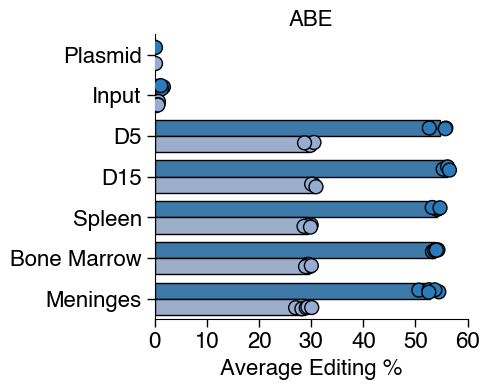

In [9]:
# ── OG screens — editing efficiency (all timepoints, figure 2e style) ─────
BASE_crispr = BASE + 'crispresso/'

ABE_og_files = os.listdir(BASE_crispr + 'og/ABE')
CBE_og_files = os.listdir(BASE_crispr + 'og/CBE')
ABE_og_files.remove('spleen_rep5_ABE.csv')  # near-zero reads, as in figure2.ipynb

name_dict_og = {
    'meninges': 'Meninges', 'spleen': 'Spleen', 'bonemarrow': 'Bone Marrow',
    'd5': 'D5', 'd15': 'D15', 'plasmidlib': 'Plasmid', 'input': 'Input',
}

ABE_og = dfs['ABE_OG'][dfs['ABE_OG']['classification'] == 'targeting guide'][['gRNA_id']]
CBE_og = dfs['CBE_OG'][dfs['CBE_OG']['classification'] == 'targeting guide'][['gRNA_id']]

t, corr, name = [], [], []
for f in ABE_og_files:
    g = pd.read_csv(BASE_crispr + f'og/ABE/{f}').rename(columns={'Guide_ID': 'gRNA_id'})
    g = pd.merge(g, ABE_og, on='gRNA_id')
    g = g[g['Reads_aligned_all_amplicons'] >= min_sensor_reads_og]
    t.append(np.average(g['target_base_edit_perc']))
    corr.append(np.average(g['corr_perc']))
    name.append(name_dict_og[f.split('_')[0]])

t2, corr2, name2 = [], [], []
for f in CBE_og_files:
    g = pd.read_csv(BASE_crispr + f'og/CBE/{f}').rename(columns={'Guide_ID': 'gRNA_id'})
    g = pd.merge(g, CBE_og, on='gRNA_id')
    g = g[g['Reads_aligned_all_amplicons'] >= min_sensor_reads_og]
    t2.append(np.average(g['target_base_edit_perc']))
    corr2.append(np.average(g['corr_perc']))
    name2.append(name_dict_og[f.split('_')[0]])

ABE_editing1 = pd.DataFrame({'Sample': name,  'Editing %': t,    'Edit Type': 'Target Editing (w/ Bystanders)'})
ABE_editing2 = pd.DataFrame({'Sample': name,  'Editing %': corr, 'Edit Type': 'Pure Correct Editing'})
ABE_og_editing = pd.concat((ABE_editing1, ABE_editing2))

CBE_editing1 = pd.DataFrame({'Sample': name2, 'Editing %': t2,    'Edit Type': 'Target Editing (w/ Bystanders)'})
CBE_editing2 = pd.DataFrame({'Sample': name2, 'Editing %': corr2, 'Edit Type': 'Pure Correct Editing'})
CBE_og_editing = pd.concat((CBE_editing1, CBE_editing2))

order_og = ['Plasmid', 'Input', 'D5', 'D15', 'Spleen', 'Bone Marrow', 'Meninges']

def _plot_editing_bar(data, title, order, palette, save_path,  save = False,):
    fig, ax = plt.subplots(1, 1, figsize=(5, 4))
    sns.barplot(data=data, y='Sample', x='Editing %', hue='Edit Type', ax=ax,
                edgecolor='black', linewidth=1, palette=palette, order=order)
    sns.stripplot(data=data, y='Sample', x='Editing %', hue='Edit Type', ax=ax,
                  edgecolor='black', linewidth=1, palette=palette, order=order, dodge=True, s=10)
    ax.set_ylabel('')
    ax.set_xticks([0, 10, 20, 30, 40, 50, 60])
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=16, direction='out', length=6, width=1)
    ax.set_title(title, fontsize=16)
    ax.set_xlabel('Average Editing %', fontsize=16)
    ax.legend([], [], frameon=False)
    fig.tight_layout()
    if save:
        fig.savefig(save_path, bbox_inches='tight')
    plt.show()

_plot_editing_bar(ABE_og_editing, 'ABE', order_og, edit_palette, BASE + 'figures_final/2e_ABE.pdf', save=False)
# _plot_editing_bar(CBE_og_editing, 'CBE', order_og, edit_palette, BASE + 'figures_final/2e_CBE.pdf')

## 2e

Waterfall plot of ABE gRNA enrichment in each sample type, with top 10 and bottom 10 gRNAs (as ranked by LFC, with FDR < 0.1) labeled. Guides with target base editing <20% excluded. Points colored by COSMIC Cancer Gene Census annotation. Point size indicates FDR value.

In [ ]:
ABE_LFC_FDR = dfs['ABE_OG']
CBE_LFC_FDR = dfs['CBE_OG']

d15
1 Pik3r3 D11G tab:grey
2 Daxx N274S tab:purple
3 Syk N451S tab:red
4 Raf1 R391G tab:red
5 Myc T73A tab:red
6 Ret K809E tab:red
7 Erbb3 Q807R tab:red
8 Keap1 Y33H tab:blue
9 Rbm10 H777R tab:blue
10 Arid5b K1026E tab:grey
786 Trp53 C138R tab:purple
787 Vhl L124P tab:blue
788 Ctnnb1 S45P tab:red
789 Braf K638E tab:red
790 Ctnnb1 S45P tab:red
791 Ctcf C384R tab:blue
792 Map2k1 F53L tab:red
793 Ctnnb1 T41A tab:red
794 Ezh2 Non-coding tab:purple
795 Vhl N44S tab:blue
1. Pik3r3 D11G
2. Daxx N274S
3. Syk N451S
4. Raf1 R391G
5. Myc T73A
6. Ret K809E
7. Erbb3 Q807R
8. Keap1 Y33H
9. Rbm10 H777R
10. Arid5b K1026E
786. Trp53 C138R
787. Vhl L124P
788. Ctnnb1 S45P
789. Braf K638E
790. Ctnnb1 S45P
791. Ctcf C384R
792. Map2k1 F53L
793. Ctnnb1 T41A
794. Ezh2 Non-coding
795. Vhl N44S
spleen
1 Ctnnb1 S45P tab:red
2 Ercc2 T484A tab:blue
3 Nfe2 Q286R tab:grey
4 Ep300 H350R tab:blue
5 Syk N451S tab:red
6 Raf1 R391G tab:red
7 Gata3 H281R tab:purple
8 Smo I160V tab:red
9 Keap1 H311R tab:blue
10 Myd88 M219T

Text(0.5, 1.0, 'Meninges')

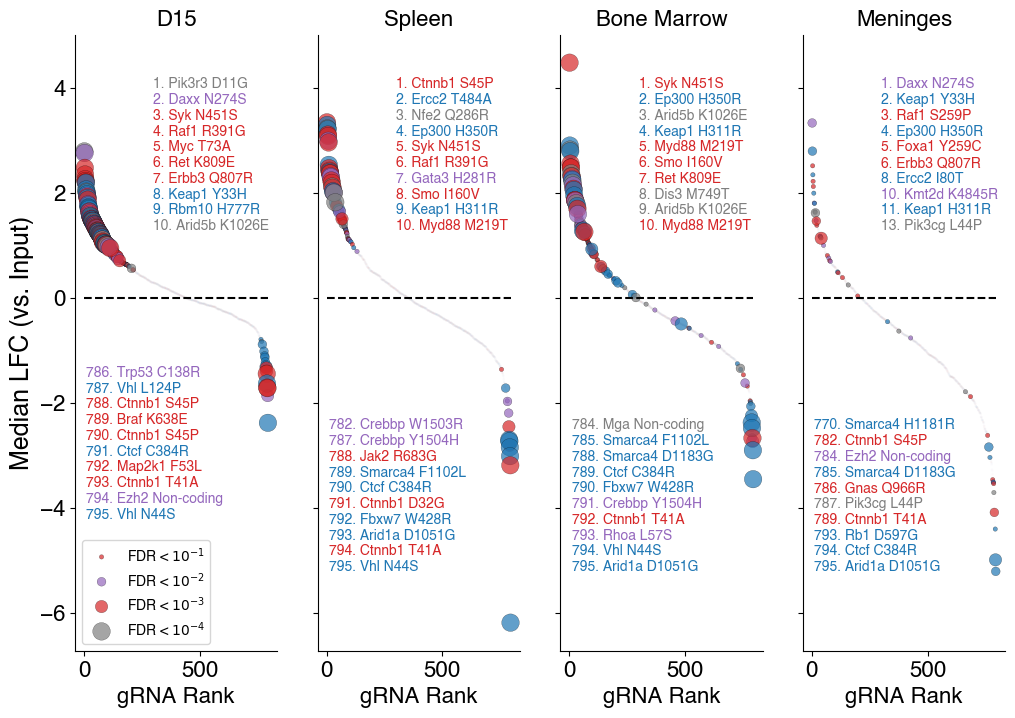

In [ ]:
import matplotlib.patheffects as PathEffects
min_edit = 20
FDR_cutoff = .1
min_input_counts = 2

ABE_targ = ABE_LFC_FDR[(ABE_LFC_FDR['classification']=='targeting guide')& (ABE_LFC_FDR['target_base_edit_perc']>=min_edit) & (ABE_LFC_FDR['Input_median']>=min_input_counts)]

#-----and plotting--------
names2 = ['d15','spleen', 'bonemarrow', 'meninges',]

color_dict = {'Oncogene':'tab:red', 'Oncogene/TSG':'tab:purple', 'TSG':'tab:blue', 'Undefined':'tab:grey'}

fig, ax = plt.subplots(1,4,figsize=(12,8), sharey=True)

for k, val in enumerate(names2):
    #cc = CBE_mageck_dict[val].rename(columns={'sgrna':'gRNA_id'})
    #cc2 = pd.merge(cc, CBE_targ, on='gRNA_id')
    #cc2 = cc2.sort_values(by='LFC', ascending=False)

    cc2 = ABE_targ.sort_values(by=f'LFC_median_{val}', ascending=False)

    cc2['Rank'] = range(1, len(cc2)+1)
    cc2['color'] = [color_dict[i] for i in cc2['Role in Cancer']]



    #split by significance level

    cc2_other = cc2[cc2[f'FDR_{val}']>=FDR_cutoff]
    ax[k].scatter(cc2_other['Rank'], cc2_other[f'LFC_median_{val}'], color=cc2_other['color'], s=1, alpha=.01)

    #FDR_cutoffs = [10**-4, 10**-3, 10**-2, 10**-1]

    FDR_cutoffs = [10**-1, 10**-2, 10**-3, 10**-4]

    size_dict = dict(zip(FDR_cutoffs, [10,40,80,160]))
    label_dict = dict(zip(FDR_cutoffs, ['FDR < $10^{-1}$', 'FDR < $10^{-2}$', 'FDR < $10^{-3}$', 'FDR < $10^{-4}$']))

   # for id1, cut in enumerate(FDR_cutoffs):
     #   if id1==0:
     #       cc2_sig = cc2[cc2[f'FDR_{val}']<cut]
     #   else:
     #       cc2_sig = cc2[(cc2[f'FDR_{val}']<cut) & (cc2[f'FDR_{val}']>=FDR_cutoffs[id1-1])]
      #  ax[k].scatter(cc2_sig['Rank'], cc2_sig[f'LFC_median_{val}'],color=cc2_sig['color'], s=size_dict[cut], label=label_dict[cut])

    for id1, cut in enumerate(FDR_cutoffs):
        if id1==3:
            cc2_sig = cc2[(cc2[f'FDR_{val}']<cut)]
            
        else:
            cc2_sig = cc2[(cc2[f'FDR_{val}']<cut) &(cc2[f'FDR_{val}']>=FDR_cutoffs[id1+1])]

        ax[k].scatter(cc2_sig['Rank'], cc2_sig[f'LFC_median_{val}'],color=cc2_sig['color'], s=size_dict[cut], label=label_dict[cut], linewidth=.2, edgecolor='black', alpha=.7)

    if k==0:
        ax[k].legend(loc='lower left')

    #------making plot pretty------

    ax[k].spines[['top', 'right']].set_visible(False)
    ax[k].tick_params(axis='both', which='major', labelsize=16,)
    ax[k].plot([1, len(cc2)+1], [0,0], linestyle='dashed', color='black')
    ax[k].set_xlabel('gRNA Rank', fontsize=16)

    #and annotate top and bottom 5 variant
    cc3 = cc2[cc2[f'FDR_{val}']<FDR_cutoff]
    top = cc3[:10]
    bottom = cc3[-10:]
    tb = pd.concat((top, bottom))

    t = []
    x = []
    y = []
    c = []

    ns = []
    print(val)
    for i, val2 in tb.iterrows():
        y.append(val2[f'LFC_median_{val}'])
        x.append(val2['Rank'])
        c.append(val2['color'])
        a = val2['HGVSp_m']
        if a=='Not calculated (legacy)':
            a = val2['HGVSp_h'] + ' (human)'
        b = val2['gene_name_m_corrected']
        t.append(f'{b} {a}')

        ns.append(f'{val2["Rank"]}. {b} {a}')
        print(f'{val2["Rank"]} {b} {a} {val2["color"]}')

    #top

    for idx, j in enumerate(ns[:10]):
        ax[k].text(300,4-idx*.3, j, color=c[idx])
        print(f'{j}')

    for idx, j in enumerate(ns[10:]):
        if k==0:
            ax[k].text(10,-1.5 -(idx*.3), j, color=c[idx+10])
            print(f'{j}')
        else:
            ax[k].text(10,-2.5 -(idx*.3), j, color=c[idx+10])
            print(f'{j}')


    #for idx, j in enumerate(ns[5:]):
        #ax[k].text()

    #texts = [ax[k].text(x[i], y[i], t[i], fontsize=12, color=c[i], path_effects=[PathEffects.withStroke(linewidth=3,foreground="w")]) for i in range(len(x))] #bbox = dict(boxstyle = 'round,pad=0.5', fc = 'white', alpha = .9)

    #adjust_text(texts, only_move={'points':'xy', 'texts':'xy'}, ax=ax[k], arrowprops=dict(arrowstyle="-", linewidth=1, alpha=1, color='black'))


#ax.set_ylim(0,20)

ax[0].set_ylabel('Median LFC (vs. Input)', fontsize=18)
ax[0].set_title('D15', fontsize=16)
ax[1].set_title('Spleen', fontsize=16)
ax[2].set_title('Bone Marrow', fontsize=16)
ax[3].set_title('Meninges', fontsize=16)

#fig.savefig('figures/2g_UPDATED.png', dpi=300, transparent=True)

## 2f

Volcano plot of ABE sgRNA enrichment and depletion in bone marrow. Axes show median LFC versus empirical −log10(FDR). Enriched (orange) and depleted (blue) gRNAs targeting leukemia-related genes are labeled.

In [83]:
LAB_DATA_ROOT = os.environ.get("LAB_DATA_ROOT", "/Users/kexindong/Documents/GitHub/Database")
df_mutation_aacr = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_mutations_extended.txt',
                          header=0, sep='\t', comment="#", 
                          na_values=['Not Applicable', 'NA', 'NULL', '-', 'None', ''])
df_pts = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_clinical_patient.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')
df_sample = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_clinical_sample.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')
# df_sv = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_sv.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')

In [84]:
sample_id_leukemia = df_sample[df_sample['CANCER_TYPE'].isin(['Leukemia', 'B-Lymphoblastic Leukemia/Lymphoma', 'T-Lymphoblastic Leukemia/Lymphoma'])]['SAMPLE_ID'].unique()
df_mutation_aacr_leukemia = df_mutation_aacr[df_mutation_aacr['Tumor_Sample_Barcode'].isin(sample_id_leukemia)].reset_index(drop=True)
df_mutation_aacr_leukemia = df_mutation_aacr_leukemia[df_mutation_aacr_leukemia['Variant_Type']== 'SNP'].reset_index(drop=True)
df_mutation_aacr_leukemia = df_mutation_aacr_leukemia[df_mutation_aacr_leukemia['Center']== 'MSK'].reset_index(drop=True)
df_mutation_aacr_leukemia

,Hugo_Symbol,Entrez_Gene_Id,Center,NCBI_Build,Chromosome,Start_Position,End_Position,Strand,Consequence,Variant_Classification,...,FILTER,Polyphen_Prediction,Polyphen_Score,SIFT_Prediction,SIFT_Score,SWISSPROT,n_depth,t_depth,Annotation_Status,mutationInCis_Flag
0,NRAS,4893.0,MSK,GRCh37,1,115258747,115258747,+,missense_variant,Missense_Mutation,...,PASS,possibly_damaging,0.525,deleterious,0.02,NaN,338.0,394.0,SUCCESS,False
1,NRAS,4893.0,MSK,GRCh37,1,115258747,115258747,+,missense_variant,Missense_Mutation,...,PASS,benign,0.339,deleterious,0.00,NaN,1450.0,1323.0,SUCCESS,False
2,HGF,3082.0,MSK,GRCh37,7,81381472,81381472,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.998,deleterious,0.00,NaN,278.0,431.0,SUCCESS,False
3,PTPN11,5781.0,MSK,GRCh37,12,112888165,112888165,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.997,deleterious,0.00,NaN,408.0,425.0,SUCCESS,False
4,NRAS,4893.0,MSK,GRCh37,1,115252204,115252204,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.933,deleterious,0.03,NaN,291.0,428.0,SUCCESS,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11140,DNMT3A,1788.0,MSK,GRCh37,2,25457242,25457242,+,missense_variant,Missense_Mutation,...,PASS,benign,0.067,deleterious,0.00,NaN,725.0,805.0,SUCCESS,False
11141,EPHA5,2044.0,MSK,GRCh37,4,66213844,66213844,+,stop_gained,Nonsense_Mutation,...,PASS,NaN,NaN,NaN,NaN,NaN,1305.0,889.0,SUCCESS,False
11142,DNMT3A,1788.0,MSK,GRCh37,2,25457242,25457242,+,missense_variant,Missense_Mutation,...,PASS,benign,0.067,deleterious,0.00,NaN,788.0,530.0,SUCCESS,False
11143,IDH1,3417.0,MSK,GRCh37,2,209113113,209113113,+,missense_variant,Missense_Mutation,...,PASS,benign,0.100,deleterious_low_confidence,0.03,NaN,760.0,691.0,SUCCESS,False


In [85]:
df_leukemia = df_mutation_aacr_leukemia[['Hugo_Symbol', 'Entrez_Gene_Id', 'Chromosome', 'Start_Position', 'End_Position', 'Reference_Allele', 'Tumor_Seq_Allele2', 'Variant_Type', 'Variant_Classification', 'Strand', 'Tumor_Sample_Barcode']].drop_duplicates().reset_index(drop=True).copy()
df_leukemia = df_leukemia[df_leukemia['Chromosome']!= 'MT'].reset_index(drop=True)
df_leukemia = df_leukemia[['Hugo_Symbol', 'Entrez_Gene_Id', 'Chromosome', 'Start_Position', 'End_Position', 'Reference_Allele', 'Tumor_Seq_Allele2', 'Variant_Type', 'Variant_Classification', 'Strand']].value_counts().reset_index()

In [86]:
df_leukemia.reset_index(drop=True)
df_leukemia.columns = df_leukemia.columns[:-1].tolist() + ['pts_count']
df_leukemia

,Hugo_Symbol,Entrez_Gene_Id,Chromosome,Start_Position,End_Position,Reference_Allele,Tumor_Seq_Allele2,Variant_Type,Variant_Classification,Strand,pts_count
0,DNMT3A,1788.0,2,25457242,25457242,C,T,SNP,Missense_Mutation,+,312
1,IDH2,3418.0,15,90631934,90631934,C,T,SNP,Missense_Mutation,+,273
2,SRSF2,6427.0,17,74732959,74732959,G,T,SNP,Missense_Mutation,+,232
3,NRAS,4893.0,1,115258747,115258747,C,T,SNP,Missense_Mutation,+,143
4,SRSF2,6427.0,17,74732959,74732959,G,A,SNP,Missense_Mutation,+,113
...,...,...,...,...,...,...,...,...,...,...,...
3869,IKZF1,10320.0,7,50468004,50468004,C,G,SNP,Nonsense_Mutation,+,1
3870,IKZF1,10320.0,7,50468065,50468065,G,A,SNP,Missense_Mutation,+,1
3871,IKZF1,10320.0,7,50468165,50468165,G,C,SNP,Missense_Mutation,+,1
3872,IKZF1,10320.0,7,50468180,50468180,T,C,SNP,Missense_Mutation,+,1


In [87]:
df_mutation_aacr = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_mutations_extended.txt',
                          header=0, sep='\t', comment="#", 
                          na_values=['Not Applicable', 'NA', 'NULL', '-', 'None', ''])
df_pts = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_clinical_patient.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')
df_sample = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_clinical_sample.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')
# df_sv = pd.read_csv(LAB_DATA_ROOT + '/PublicDatabase/AACR-GENIE/v17.0/data_sv.txt', header=0, sep='\t', comment="#", na_values = 'Not Applicable')

In [88]:
sample_id_leukemia = df_sample[df_sample['CANCER_TYPE'].isin(['Leukemia', 'B-Lymphoblastic Leukemia/Lymphoma', 'T-Lymphoblastic Leukemia/Lymphoma'])]['SAMPLE_ID'].unique()
df_mutation_aacr_leukemia = df_mutation_aacr[df_mutation_aacr['Tumor_Sample_Barcode'].isin(sample_id_leukemia)].reset_index(drop=True)
df_mutation_aacr_leukemia = df_mutation_aacr_leukemia[df_mutation_aacr_leukemia['Variant_Type']== 'SNP'].reset_index(drop=True)
df_mutation_aacr_leukemia = df_mutation_aacr_leukemia[df_mutation_aacr_leukemia['Center']== 'MSK'].reset_index(drop=True)
df_mutation_aacr_leukemia

,Hugo_Symbol,Entrez_Gene_Id,Center,NCBI_Build,Chromosome,Start_Position,End_Position,Strand,Consequence,Variant_Classification,...,FILTER,Polyphen_Prediction,Polyphen_Score,SIFT_Prediction,SIFT_Score,SWISSPROT,n_depth,t_depth,Annotation_Status,mutationInCis_Flag
0,NRAS,4893.0,MSK,GRCh37,1,115258747,115258747,+,missense_variant,Missense_Mutation,...,PASS,possibly_damaging,0.525,deleterious,0.02,NaN,338.0,394.0,SUCCESS,False
1,NRAS,4893.0,MSK,GRCh37,1,115258747,115258747,+,missense_variant,Missense_Mutation,...,PASS,benign,0.339,deleterious,0.00,NaN,1450.0,1323.0,SUCCESS,False
2,HGF,3082.0,MSK,GRCh37,7,81381472,81381472,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.998,deleterious,0.00,NaN,278.0,431.0,SUCCESS,False
3,PTPN11,5781.0,MSK,GRCh37,12,112888165,112888165,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.997,deleterious,0.00,NaN,408.0,425.0,SUCCESS,False
4,NRAS,4893.0,MSK,GRCh37,1,115252204,115252204,+,missense_variant,Missense_Mutation,...,PASS,probably_damaging,0.933,deleterious,0.03,NaN,291.0,428.0,SUCCESS,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11140,DNMT3A,1788.0,MSK,GRCh37,2,25457242,25457242,+,missense_variant,Missense_Mutation,...,PASS,benign,0.067,deleterious,0.00,NaN,725.0,805.0,SUCCESS,False
11141,EPHA5,2044.0,MSK,GRCh37,4,66213844,66213844,+,stop_gained,Nonsense_Mutation,...,PASS,NaN,NaN,NaN,NaN,NaN,1305.0,889.0,SUCCESS,False
11142,DNMT3A,1788.0,MSK,GRCh37,2,25457242,25457242,+,missense_variant,Missense_Mutation,...,PASS,benign,0.067,deleterious,0.00,NaN,788.0,530.0,SUCCESS,False
11143,IDH1,3417.0,MSK,GRCh37,2,209113113,209113113,+,missense_variant,Missense_Mutation,...,PASS,benign,0.100,deleterious_low_confidence,0.03,NaN,760.0,691.0,SUCCESS,False


In [89]:
df_leukemia = df_mutation_aacr_leukemia[['Hugo_Symbol', 'Entrez_Gene_Id', 'Chromosome', 'Start_Position', 'End_Position', 'Reference_Allele', 'Tumor_Seq_Allele2', 'Variant_Type', 'Variant_Classification', 'Strand', 'Tumor_Sample_Barcode']].drop_duplicates().reset_index(drop=True).copy()
df_leukemia = df_leukemia[df_leukemia['Chromosome']!= 'MT'].reset_index(drop=True)
df_leukemia = df_leukemia[['Hugo_Symbol', 'Entrez_Gene_Id', 'Chromosome', 'Start_Position', 'End_Position', 'Reference_Allele', 'Tumor_Seq_Allele2', 'Variant_Type', 'Variant_Classification', 'Strand']].value_counts().reset_index()

In [90]:
df_leukemia.reset_index(drop=True)
df_leukemia.columns = df_leukemia.columns[:-1].tolist() + ['pts_count']
df_leukemia

,Hugo_Symbol,Entrez_Gene_Id,Chromosome,Start_Position,End_Position,Reference_Allele,Tumor_Seq_Allele2,Variant_Type,Variant_Classification,Strand,pts_count
0,DNMT3A,1788.0,2,25457242,25457242,C,T,SNP,Missense_Mutation,+,312
1,IDH2,3418.0,15,90631934,90631934,C,T,SNP,Missense_Mutation,+,273
2,SRSF2,6427.0,17,74732959,74732959,G,T,SNP,Missense_Mutation,+,232
3,NRAS,4893.0,1,115258747,115258747,C,T,SNP,Missense_Mutation,+,143
4,SRSF2,6427.0,17,74732959,74732959,G,A,SNP,Missense_Mutation,+,113
...,...,...,...,...,...,...,...,...,...,...,...
3869,IKZF1,10320.0,7,50468004,50468004,C,G,SNP,Nonsense_Mutation,+,1
3870,IKZF1,10320.0,7,50468065,50468065,G,A,SNP,Missense_Mutation,+,1
3871,IKZF1,10320.0,7,50468165,50468165,G,C,SNP,Missense_Mutation,+,1
3872,IKZF1,10320.0,7,50468180,50468180,T,C,SNP,Missense_Mutation,+,1


### To label all hits

In [ ]:
from adjustText import adjust_text

min_edit   = 20
min_input  = 10
FDR_cutoff = 0.1
LFC_cutoff = 1.0

leukemia_genes = set(df_leukemia['Hugo_Symbol'].dropna().unique())

conditions_emp = ['d15', 'bm', 'spleen', 'men']
titles         = ['D15', 'Bone Marrow', 'Spleen', 'Meninges']

df = dfs['CBE_OG']
targ = df[
    (df['classification'] == 'targeting guide') &
    (df['Input_median'] >= min_input) &
    (df['target_base_edit_perc_d5'] >= min_edit)
].copy()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, cond, title in zip(axes, conditions_emp, titles):
    lfc_col = f'LFC_median_{cond}'
    fdr_col = f'FDR_{cond}_fishers'

    sub = targ[[lfc_col, fdr_col, 'gene_name_h', 'gene_name_m_corrected', 'HGVSp_m', 'HGVSp_h']].dropna(subset=[lfc_col, fdr_col]).copy()
    sub['neg_log10_fdr'] = -np.log10(sub[fdr_col].clip(lower=1e-300))

    is_hit     = (sub[fdr_col] < FDR_cutoff) & (sub[lfc_col].abs() >= LFC_cutoff)
    is_enrich  = is_hit & (sub[lfc_col] > 0)
    is_deplete = is_hit & (sub[lfc_col] < 0)
    is_leuk    = is_hit & sub['gene_name_h'].isin(leukemia_genes)

    # All non-hits: grey
    ax.scatter(sub.loc[~is_hit, lfc_col], sub.loc[~is_hit, 'neg_log10_fdr'],
               color='lightgrey', s=10, linewidths=0, zorder=1)
    # Hits not in leukemia genes: grey
    ax.scatter(sub.loc[is_hit & ~is_leuk, lfc_col], sub.loc[is_hit & ~is_leuk, 'neg_log10_fdr'],
               color='lightgrey', s=15, linewidths=0, zorder=2)
    # Leukemia enriched hits: red with black stroke
    ax.scatter(sub.loc[is_leuk & is_enrich, lfc_col], sub.loc[is_leuk & is_enrich, 'neg_log10_fdr'],
               color=reds[2], edgecolors='black', linewidths=0.5, s=50, zorder=4)
    # Leukemia depleted hits: blue with black stroke
    ax.scatter(sub.loc[is_leuk & is_deplete, lfc_col], sub.loc[is_leuk & is_deplete, 'neg_log10_fdr'],
               color=blues[2], edgecolors='black', linewidths=0.5, s=50, zorder=4)

    # Threshold lines
    ax.axhline(-np.log10(FDR_cutoff), color='grey', lw=0.8, ls='--')
    ax.axvline( LFC_cutoff, color='grey', lw=0.8, ls='--')
    ax.axvline(-LFC_cutoff, color='grey', lw=0.8, ls='--')

    # Label all hits (enriched=red, depleted=blue)
    to_label = sub[is_hit]

    texts = []
    for _, row in to_label.iterrows():
        mut = row['HGVSp_m']
        if pd.isna(mut) or mut in ('Non-coding', 'Not calculated (legacy)'):
            mut = str(row['HGVSp_h']) + ' (H)'
        label = f"{row['gene_name_m_corrected']} {mut}"
        color = reds[2] if row[lfc_col] > 0 else blues[2]
        texts.append(ax.text(row[lfc_col], row['neg_log10_fdr'], label,
                             fontsize=7, color=color, zorder=5))
    if texts:
        adjust_text(texts, ax=ax,
                    arrowprops=dict(arrowstyle='-', color='black', lw=0.5))

    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Median LFC (vs. Input)', fontsize=12)
    if ax is axes[0]:
        ax.set_ylabel('-log10(FDR)', fontsize=12)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=11)

fig.suptitle(f'CBE OG — Leukemia gene hits highlighted (FDR<{FDR_cutoff}, |LFC|≥{LFC_cutoff}, edit≥{min_edit}%)',
             fontsize=13, y=1.02)
fig.tight_layout()
# fig.savefig(BASE + 'figures_final/volcano_leukemia_ABE.pdf', bbox_inches='tight')
plt.show()


2 [0.55488685 0.14630879]
8 [-0.74670748 -0.80453817]


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


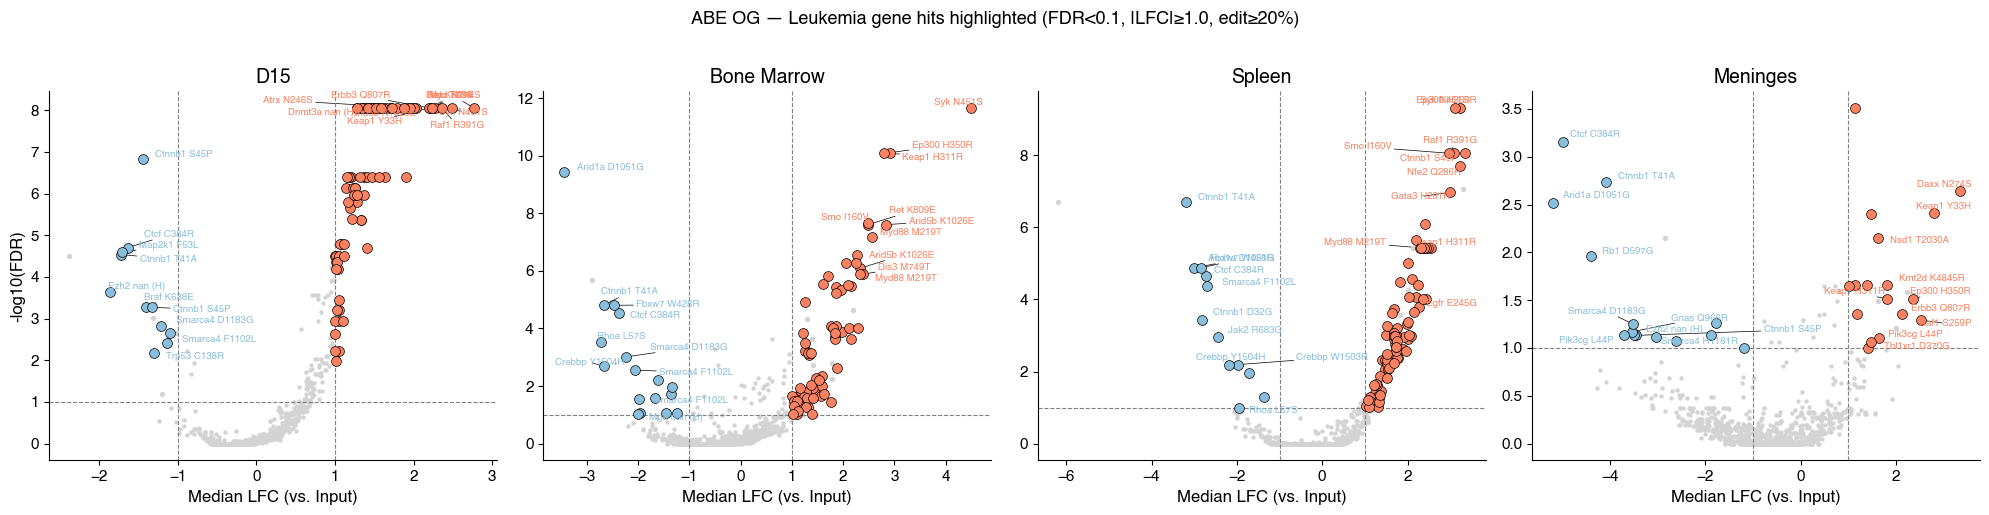

In [ ]:
from adjustText import adjust_text

min_edit   = 20
min_input  = 10
FDR_cutoff = 0.1
LFC_cutoff = 1.0

# Leukemia gene list from MSK-IMPACT clinical data
leukemia_genes = set(df_leukemia['Hugo_Symbol'].dropna().unique())

conditions_emp = ['d15', 'bm', 'spleen', 'men']
titles         = ['D15', 'Bone Marrow', 'Spleen', 'Meninges']

df = dfs['ABE_OG']
targ = df[
    (df['classification'] == 'targeting guide') &
    (df['Input_median'] >= min_input) &
    (df['target_base_edit_perc_d5'] >= min_edit)
].copy()

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

for ax, cond, title in zip(axes, conditions_emp, titles):
    lfc_col = f'LFC_median_{cond}'
    fdr_col = f'FDR_{cond}_fishers'

    sub = targ[[lfc_col, fdr_col, 'gene_name_h', 'gene_name_m_corrected', 'HGVSp_m', 'HGVSp_h']].dropna(subset=[lfc_col, fdr_col]).copy()
    sub['neg_log10_fdr'] = -np.log10(sub[fdr_col].clip(lower=1e-300))

    is_hit     = (sub[fdr_col] < FDR_cutoff) & (sub[lfc_col].abs() >= LFC_cutoff)
    is_enrich  = is_hit & (sub[lfc_col] > 0)
    is_deplete = is_hit & (sub[lfc_col] < 0)
    is_leuk    = is_hit & sub['gene_name_h'].isin(leukemia_genes)

    # All non-hits: grey
    ax.scatter(sub.loc[~is_hit, lfc_col], sub.loc[~is_hit, 'neg_log10_fdr'],
               color='lightgrey', s=10, linewidths=0, zorder=1)
    # Hits not in leukemia genes: grey
    ax.scatter(sub.loc[is_hit & ~is_leuk, lfc_col], sub.loc[is_hit & ~is_leuk, 'neg_log10_fdr'],
               color='lightgrey', s=15, linewidths=0, zorder=2)
    # Leukemia enriched hits: red with black stroke
    ax.scatter(sub.loc[is_leuk & is_enrich, lfc_col], sub.loc[is_leuk & is_enrich, 'neg_log10_fdr'],
               color=reds[2], edgecolors='black', linewidths=0.5, s=50, zorder=4)
    # Leukemia depleted hits: blue with black stroke
    ax.scatter(sub.loc[is_leuk & is_deplete, lfc_col], sub.loc[is_leuk & is_deplete, 'neg_log10_fdr'],
               color=blues[2], edgecolors='black', linewidths=0.5, s=50, zorder=4)

    # Threshold lines
    ax.axhline(-np.log10(FDR_cutoff), color='grey', lw=0.8, ls='--')
    ax.axvline( LFC_cutoff, color='grey', lw=0.8, ls='--')
    ax.axvline(-LFC_cutoff, color='grey', lw=0.8, ls='--')

    # Label top 10 enrichers and top 10 depleters among leukemia hits
    leuk_enrich = sub[is_leuk & is_enrich].sort_values(lfc_col, ascending=False).head(10)
    leuk_deplete = sub[is_leuk & is_deplete].sort_values(lfc_col, ascending=True).head(10)
    to_label = pd.concat([leuk_enrich, leuk_deplete])

    texts = []
    for _, row in to_label.iterrows():
        mut = row['HGVSp_m']
        if pd.isna(mut) or mut in ('Non-coding', 'Not calculated (legacy)'):
            mut = str(row['HGVSp_h']) + ' (H)'
        label = f"{row['gene_name_m_corrected']} {mut}"
        color = reds[2] if row[lfc_col] > 0 else blues[2]
        texts.append(ax.text(row[lfc_col], row['neg_log10_fdr'], label,
                             fontsize=7, color=color, zorder=5))
    if texts:
        adjust_text(texts, ax=ax,
                    arrowprops=dict(arrowstyle='-', color='black', lw=0.5))

    ax.set_title(title, fontsize=14)
    ax.set_xlabel('Median LFC (vs. Input)', fontsize=12)
    if ax is axes[0]:
        ax.set_ylabel('-log10(FDR)', fontsize=12)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=11)

fig.suptitle(f'ABE OG — Leukemia gene hits highlighted (FDR<{FDR_cutoff}, |LFC|≥{LFC_cutoff}, edit≥{min_edit}%)',
             fontsize=13, y=1.02)
fig.tight_layout()
fig.savefig(BASE + 'figures_final/volcano_leukemia_ABE.pdf', bbox_inches='tight')
plt.show()


Looks like you are using a tranform that doesn't support FancyArrowPatch, using ax.annotate instead. The arrows might strike through texts. Increasing shrinkA in arrowprops might help.
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


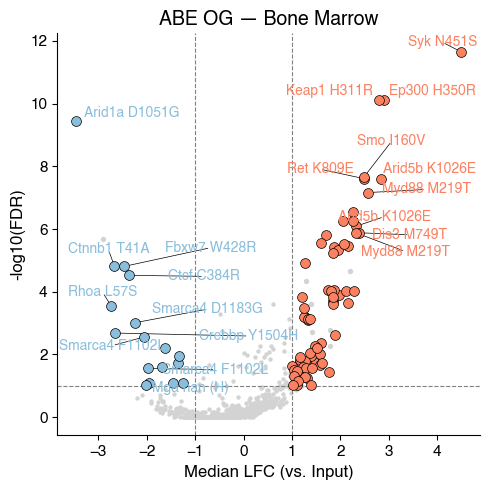

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
Zapf NOT subset; don't know how to subset; dropped
feat NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


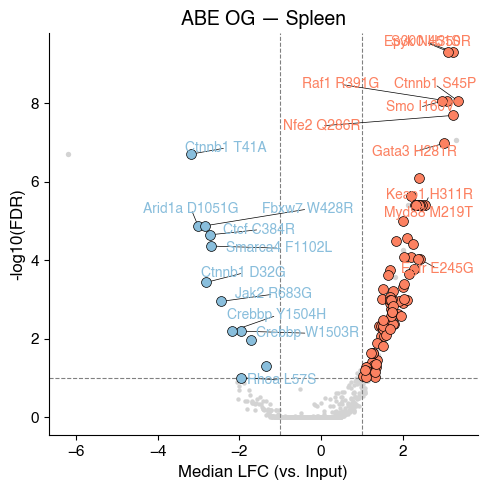

In [ ]:
from adjustText import adjust_text

min_edit   = 20
min_input  = 10
FDR_cutoff = 0.1
LFC_cutoff = 1.0

leukemia_genes = set(df_leukemia['Hugo_Symbol'].dropna().unique())

df = dfs['ABE_OG']
targ = df[
    (df['classification'] == 'targeting guide') &
    (df['Input_median'] >= min_input) &
    (df['target_base_edit_perc_d5'] >= min_edit)
].copy()

for cond, title in [('bm', 'Bone Marrow'), ('spleen', 'Spleen')]:
    lfc_col = f'LFC_median_{cond}'
    fdr_col = f'FDR_{cond}_fishers'

    sub = targ[[lfc_col, fdr_col, 'gene_name_h', 'gene_name_m_corrected', 'HGVSp_m', 'HGVSp_h']].dropna(subset=[lfc_col, fdr_col]).copy()
    sub['neg_log10_fdr'] = -np.log10(sub[fdr_col].clip(lower=1e-300))

    is_hit     = (sub[fdr_col] < FDR_cutoff) & (sub[lfc_col].abs() >= LFC_cutoff)
    is_enrich  = is_hit & (sub[lfc_col] > 0)
    is_deplete = is_hit & (sub[lfc_col] < 0)
    is_leuk    = is_hit & sub['gene_name_h'].isin(leukemia_genes)

    fig, ax = plt.subplots(1, 1, figsize=(5, 5))

    ax.scatter(sub.loc[~is_hit, lfc_col], sub.loc[~is_hit, 'neg_log10_fdr'],
               color='lightgrey', s=10, linewidths=0, zorder=1)
    ax.scatter(sub.loc[is_hit & ~is_leuk, lfc_col], sub.loc[is_hit & ~is_leuk, 'neg_log10_fdr'],
               color='lightgrey', s=15, linewidths=0, zorder=2)
    ax.scatter(sub.loc[is_leuk & is_enrich, lfc_col], sub.loc[is_leuk & is_enrich, 'neg_log10_fdr'],
               color=reds[2], edgecolors='black', linewidths=0.5, s=50, zorder=4)
    ax.scatter(sub.loc[is_leuk & is_deplete, lfc_col], sub.loc[is_leuk & is_deplete, 'neg_log10_fdr'],
               color=blues[2], edgecolors='black', linewidths=0.5, s=50, zorder=4)

    ax.axhline(-np.log10(FDR_cutoff), color='grey', lw=0.8, ls='--')
    ax.axvline( LFC_cutoff, color='grey', lw=0.8, ls='--')
    ax.axvline(-LFC_cutoff, color='grey', lw=0.8, ls='--')

    leuk_enrich  = sub[is_leuk & is_enrich].sort_values(lfc_col, ascending=False).head(10)
    leuk_deplete = sub[is_leuk & is_deplete].sort_values(lfc_col, ascending=True).head(10)
    to_label = pd.concat([leuk_enrich, leuk_deplete])

    texts = []
    for _, row in to_label.iterrows():
        mut = row['HGVSp_m']
        if pd.isna(mut) or mut in ('Non-coding', 'Not calculated (legacy)'):
            mut = str(row['HGVSp_h']) + ' (H)'
        label = f"{row['gene_name_m_corrected']} {mut}"
        color = reds[2] if row[lfc_col] > 0 else blues[2]
        texts.append(ax.text(row[lfc_col], row['neg_log10_fdr'], label,
                             fontsize=10, color=color, zorder=5))
    if texts:
        adjust_text(texts, ax=ax,
                    expand_points=(2, 2), expand_text=(1.5, 1.5),
                    force_points=(0.5, 0.5), force_text=(0.5, 0.5),
                    arrowprops=dict(arrowstyle='-', color='black', lw=0.5))


    ax.set_title(f'ABE OG — {title}', fontsize=14)
    ax.set_xlabel('Median LFC (vs. Input)', fontsize=12)
    ax.set_ylabel('-log10(FDR)', fontsize=12)
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(axis='both', which='major', labelsize=11)

    fig.tight_layout()
    fig.savefig(BASE + f'figures_final/volcano_leukemia_ABE_{cond}.pdf', bbox_inches='tight')
    plt.show()


## Additional volcano plots (filtered, targeting only)